In [70]:
import matplotlib.pyplot as plt
import networkx as nx
from sknetwork.hierarchy import Paris, LouvainHierarchy
import numpy as np
import seaborn as sns
from scipy.sparse import csr_matrix
import random
from IPython.display import SVG, display
from sknetwork.hierarchy import Paris, cut_straight, dasgupta_score, tree_sampling_divergence
from sknetwork.visualization import svg_graph, svg_bigraph, svg_dendrogram
import pandas as pd

In [118]:
g1 = nx.gnm_random_graph(40, 400, seed=42)
g2 = nx.gnm_random_graph(40, 600, seed=1)

In [119]:
for (u, v) in g1.edges():
    g1.edges[u,v]['weight'] = random.randint(0,10)/10.0
    
for (u, v) in g2.edges():
    g2.edges[u,v]['weight'] = random.randint(0,10)/10.0

In [129]:
image = svg_graph(csr_matrix(nx.adjacency_matrix(g1).toarray()), np.array([k for k in nx.kamada_kawai_layout(g1).values()]), edge_width_min=0.01, edge_width_max=2, labels=g1.nodes())
display(SVG(image))

TypeError: '>=' not supported between instances of 'NodeView' and 'int'

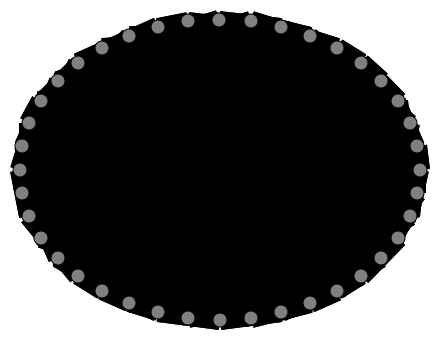

In [115]:
image = svg_graph(csr_matrix(nx.adjacency_matrix(g2).toarray()), np.array([k for k in nx.kamada_kawai_layout(g2).values()]))
display(SVG(image))

In [116]:
def clustering(graph, n_clusters, alg):
    if alg == 'paris':
        alg = Paris()
    elif alg == 'louvain':
        alg = LouvainHierarchy()
    dendrogram = alg.fit_predict(nx.adjacency_matrix(graph).toarray())
    image = svg_dendrogram(dendrogram, names=list(graph.nodes), width=600, n_clusters=n_clusters)
    display(SVG(image))
    return cut_straight(dendrogram, n_clusters=n_clusters)

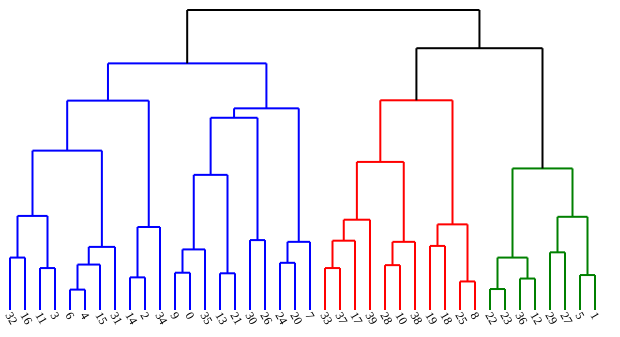

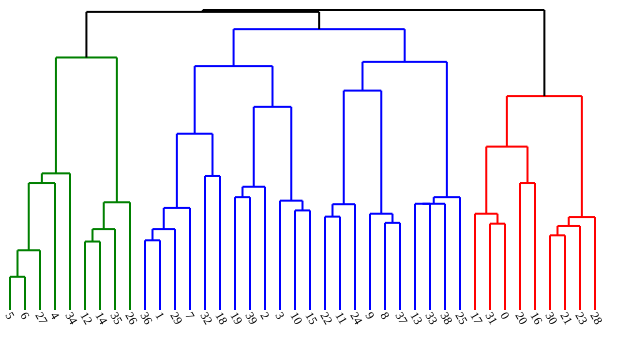

In [83]:
labels1 = clustering(g1, 3, 'paris')
labels2 = clustering(g2, 3, 'paris')

In [84]:
def jaccard_similarity(set1, set2):
    c = set1.intersection(set2)
    d = set1.union(set2)
    return len(c) / len(d)

In [85]:
def cluster_similarity_report(g1, g2, g1_n_clusters, g2_n_clusters, g1_labels, g2_labels):
    g1_clusters = [set() for _ in range(g1_n_clusters)]
    g2_clusters = [set() for _ in range(g2_n_clusters)]
    for node, clas in zip(g1.nodes, g1_labels):
        g1_clusters[clas].add(node)
    for node, clas in zip(g2.nodes, g2_labels):
        g2_clusters[clas].add(node)
    similarities = np.zeros((g1_n_clusters, g2_n_clusters))
    for i, g1_cluster in enumerate(g1_clusters):
        for j, g2_cluster in enumerate(g2_clusters):
            sim = jaccard_similarity(g1_cluster, g2_cluster)
            similarities[i, j] = sim
    return similarities, g1_clusters, g2_clusters


In [86]:
report, g1_clusters, g2_clusters = cluster_similarity_report(g1, g2, 3, 3, labels1, labels2)

Text(50.722222222222214, 0.5, 'g1')

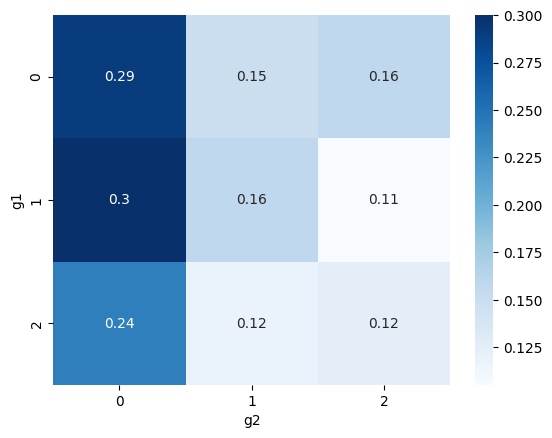

In [54]:
ax = sns.heatmap(report, annot=True, cmap='Blues')
ax.set_xlabel('g2')
ax.set_ylabel('g1')

In [65]:
g1_n = 1
g2_n = 0
print(sorted(g1_clusters[g1_n]))
print(sorted(g2_clusters[g2_n]))


[0, 1, 2, 5, 7, 14, 16, 19, 21, 24, 30, 31, 35, 37]
[1, 2, 8, 11, 12, 13, 14, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30, 32, 33, 34, 35, 36, 37, 39]
